In [1]:
import requests
import pandas as pd

api_key = "07c3190265365abee028e277fae92d06"   # paste your own key

lat, lon = 18.184135, 74.610764   # example coords (Pune area)

api_url = f"http://api.openweathermap.org/data/2.5/forecast?lat={lat}&lon={lon}&appid={api_key}"
response = requests.get(api_url)
weather_data = response.json()

print(weather_data.keys())
print(weather_data['list'][0])

dict_keys(['cod', 'message', 'cnt', 'list', 'city'])
{'dt': 1791784800, 'main': {'temp': 305.95, 'feels_like': 304.12, 'temp_min': 305.95, 'temp_max': 305.95, 'pressure': 1016, 'sea_level': 1016, 'grnd_level': 953, 'humidity': 23, 'temp_kf': 0, 'dew_point': 282.11}, 'weather': [{'id': 800, 'main': 'Clear', 'description': 'clear sky', 'icon': '01d'}], 'clouds': {'all': 4}, 'wind': {'speed': 5.68, 'deg': 88, 'gust': 6.4}, 'visibility': 10000, 'pop': 0, 'sys': {'pod': 'd'}, 'dt_txt': '2026-10-12 06:00:00'}


In [2]:
timestamps  = [pd.to_datetime(item['dt'], unit='s') for item in weather_data['list']]
temperature = [item['main']['temp'] for item in weather_data['list']]
humidity    = [item['main']['humidity'] for item in weather_data['list']]
wind_speed  = [item['wind']['speed'] for item in weather_data['list']]
weather_desc= [item['weather'][0]['description'] for item in weather_data['list']]

weather_df = pd.DataFrame({
    'Timestamp': timestamps,
    'Temperature': temperature,
    'humidity': humidity,
    'wind_speed': wind_speed,
    'weather_description': weather_desc
})
weather_df.set_index('Timestamp', inplace=True)
weather_df.head()

,Temperature,humidity,wind_speed,weather_description
Timestamp,,,,
2026-10-12 06:00:00,305.95,23,5.68,clear sky
2026-10-12 09:00:00,306.59,22,5.06,few clouds
2026-10-12 12:00:00,306.32,22,5.06,few clouds
2026-10-12 15:00:00,301.06,31,4.30,clear sky
2026-10-12 18:00:00,299.22,38,3.76,clear sky


In [3]:
# Handle missing values
weather_df.fillna(0, inplace=True)

# Convert Kelvin -> Celsius
weather_df['Temperature'] = weather_df['Temperature'] - 273.15

print("Max Temp (°C):", weather_df['Temperature'].max())
print("Min Temp (°C):", weather_df['Temperature'].min())
weather_df

Max Temp (°C): 34.94
Min Temp (°C): 22.04000000000002


,Temperature,humidity,wind_speed,weather_description
Timestamp,,,,
2026-10-12 06:00:00,32.80,23,5.68,clear sky
2026-10-12 09:00:00,33.44,22,5.06,few clouds
2026-10-12 12:00:00,33.17,22,5.06,few clouds
2026-10-12 15:00:00,27.91,31,4.30,clear sky
2026-10-12 18:00:00,26.07,38,3.76,clear sky
2026-10-12 21:00:00,23.91,51,1.84,clear sky
2026-10-13 00:00:00,23.13,57,1.37,clear sky
2026-10-13 03:00:00,27.28,46,2.42,clear sky
2026-10-13 06:00:00,32.40,29,3.98,clear sky


In [4]:
daily_mean_temp = weather_df['Temperature'].resample('D').mean()
daily_mean_humidity = weather_df['humidity'].resample('D').mean()
daily_mean_wind = weather_df['wind_speed'].resample('D').mean()

print(daily_mean_temp)

Timestamp
2026-10-12    29.5500
2026-10-13    28.6875
2026-10-14    28.2675
2026-10-15    28.4150
2026-10-16    28.1375
2026-10-17    23.9950
Freq: D, Name: Temperature, dtype: float64


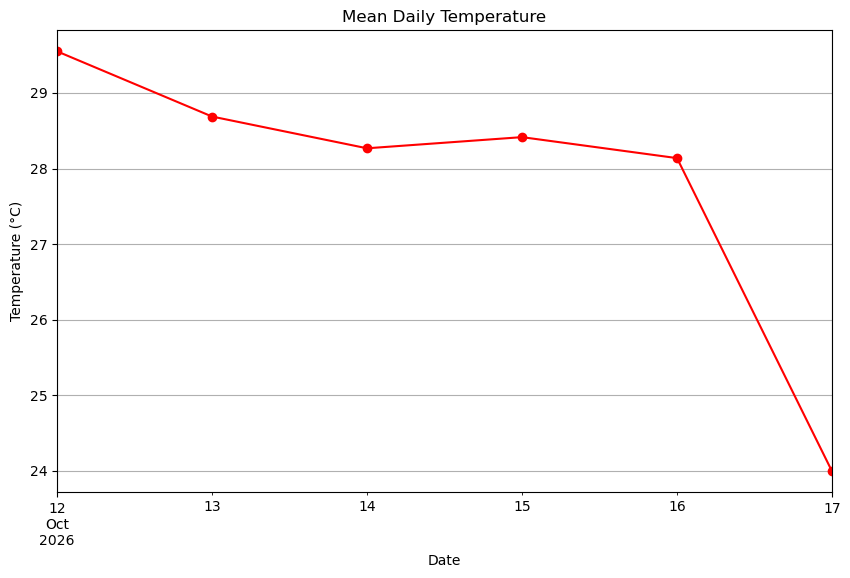

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
daily_mean_temp.plot(color='red', linestyle='-', marker='o')
plt.title('Mean Daily Temperature')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.show()

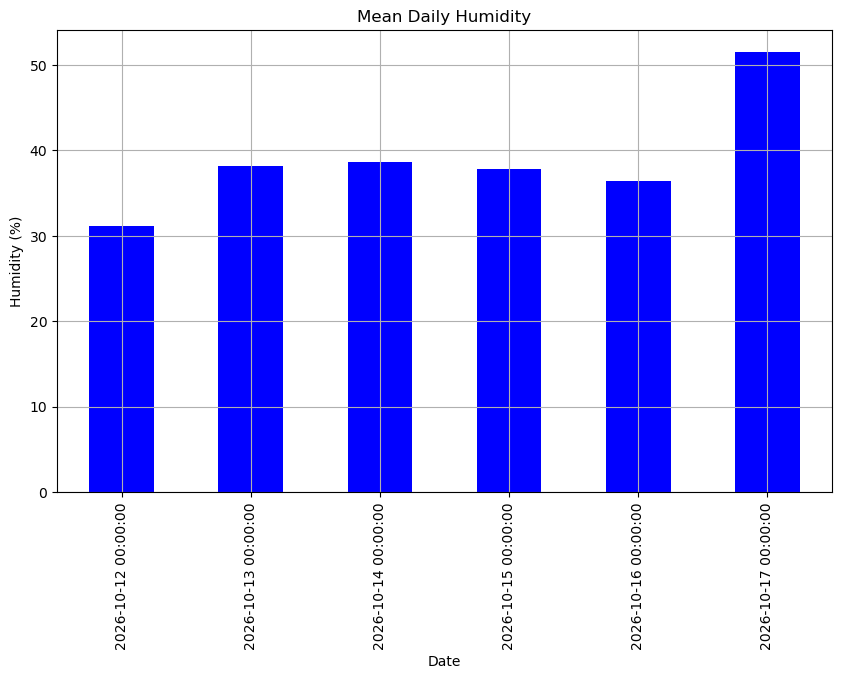

In [6]:
plt.figure(figsize=(10,6))
daily_mean_humidity.plot(kind='bar', color='blue')
plt.title('Mean Daily Humidity')
plt.xlabel('Date')
plt.ylabel('Humidity (%)')
plt.grid(True)
plt.show()

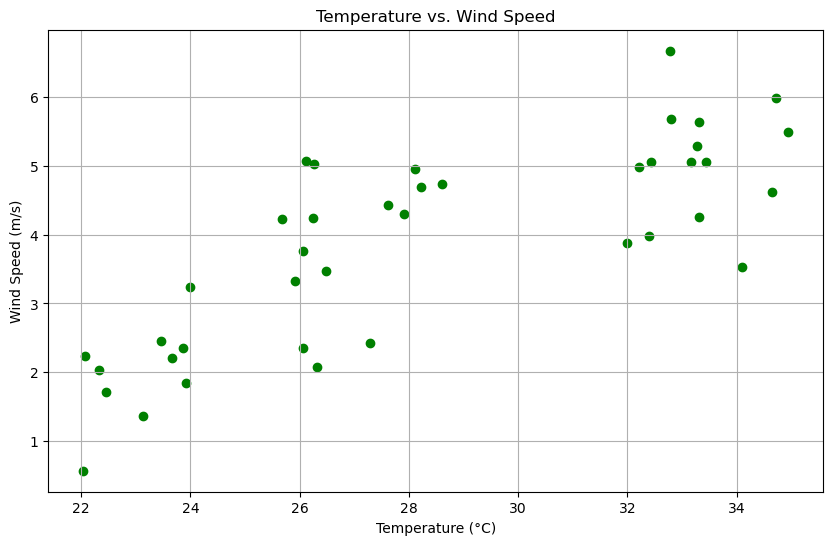

In [7]:
plt.figure(figsize=(10,6))
plt.scatter(weather_df['Temperature'], weather_df['wind_speed'], color='green')
plt.title('Temperature vs. Wind Speed')
plt.xlabel('Temperature (°C)')
plt.ylabel('Wind Speed (m/s)')
plt.grid(True)
plt.show()

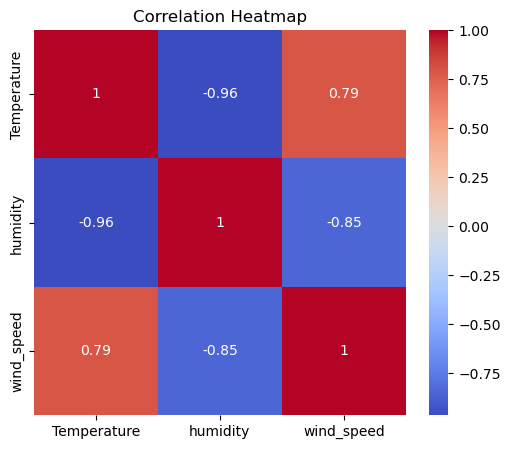

In [8]:
import seaborn as sns

corr = weather_df[['Temperature', 'humidity', 'wind_speed']].corr()
plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [9]:
import pandas as pd

locations = ['Pune', 'Lonavla', 'Satara']
rows = []

for location in locations:
    url = f'http://api.openweathermap.org/data/2.5/weather?q={location}&appid={api_key}'
    resp = requests.get(url).json()
    rows.append({
        'Location': location,
        'Temperature': resp['main']['temp'] - 273.15,   # Celsius
        'Humidity': resp['main']['humidity'],
        'Wind Speed': resp['wind']['speed'],
        'Latitude': resp['coord']['lat'],
        'Longitude': resp['coord']['lon']
    })

city_weather_df = pd.DataFrame(rows)
city_weather_df

,Location,Temperature,Humidity,Wind Speed,Latitude,Longitude
0,Pune,33.32,26,4.18,18.5196,73.8553
1,Lonavla,32.19,40,5.87,18.7500,73.4167
2,Satara,30.41,32,6.29,17.6833,73.9833


In [10]:
pip install folium


   -------------------- ------------------- 1/2 [folium]
   ---------------------------------------- 2/2 [folium]

Note: you may need to restart the kernel to use updated packages.


In [11]:
import folium

map_center = [city_weather_df['Latitude'].mean(), city_weather_df['Longitude'].mean()]
weather_map = folium.Map(location=map_center, zoom_start=2)

for _, row in city_weather_df.iterrows():
    popup_text = f"{row['Location']}: {row['Temperature']:.1f}°C, Humidity {row['Humidity']}%"
    folium.Marker(
        [row['Latitude'], row['Longitude']],
        popup=popup_text,
        icon=folium.Icon(icon='cloud', color='red')
    ).add_to(weather_map)

weather_map